# baseline vs task HR/HRV metrics

In [ ]:
# libraries

import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
from scipy.stats import norm

In [19]:
task_folder = r"physiological_data"
baseline_folder = rf'{task_folder}/baseline'

participants = ["S02", "S03", "S04", "S05", "S06", "S07", "S08", "S11", "S15", 
              "S20", "S23", "S24", "S28", "S34", "S37", "S42", "S44", "S45", 
              "S47", "S49", "S51", "S54", "S55", "S57", "S64", "S65"]
                # exluded S01, S18 a priori bc of >5% ectopic beats previously identified
                
targets = ['P03_joy', 'P29_joy', 'P34_joy', 'P42_joy', 'P44_joy',
           'P12_sadness', 'P15_sadness', 'P27_sadness', 'P34_sadness', 'P44_sadness', 
           'P03_anger', 'P15_anger', 'P22_anger', 'P38_anger', 'P42_anger',
           'P17_pride', 'P22_pride', 'P29_pride', 'P42_pride', 'P44_pride',
           'P03_shame', 'P22_shame', 'P37_shame', 'P38_shame', 'P45_shame', 
           'P12_neutral', 'P17_neutral', 'P29_neutral', 'P34_neutral', 'P38_neutral']

baseline_start = 120 # starts at 2 min (first minute is checking physio sensors, extending to avoid noise)
baseline_end = 300 # ends at 5 min

perceiver_label = 'ECG, X, RSPEC-R' # ecg channel 

In [ ]:
# helper functions copied from other analysis files

# determines if two intervals overlap (from biotop) => this will help to remove invalid areas (e.g., noisy signal) from data (later)
def does_overlap(intv1, intv2):
    (a1, b1) = intv1
    if a1 > b1: (a1, b1) = (b1, a1)
    (a2, b2) = intv2
    if a2 > b2: (a2, b2) = (b2, a2)
    overlapmin = max([a1, a2])
    overlapmax = min([b1, b2])
    return overlapmin <= overlapmax # true if overlap

# filter out any interval overlapping with invalid area
def exclude_invalid(peak_times, invalid_areas):
    valid_intervals = []
    for i in range(len(peak_times) - 1):  # -1 so it does not go out of range
        start_time = peak_times[i]  # peak 1
        end_time = peak_times[i + 1]  # peak 2
        interval = (start_time, end_time)
        if any(does_overlap(interval, invalid_area) for invalid_area in invalid_areas):
            valid_intervals.append((start_time, np.nan)) # marking the end as NaN to signal not to use it
        else:
            valid_intervals.append(interval)  # if not overlap with invalid area, add to list
    return valid_intervals

# define peak times and RR intervals
def calculate_valid_RRs(ecg_data, label):
    
    # ensure the peaks are paired with their 'valid' flags - and sorted by time first thing first
    peaks = sorted(ecg_data['peaks'][label], key=lambda p: p['t'])
    
    peak_times = np.array([peak['t'] for peak in peaks]) # identify peak times
    invalid_areas = [(a['start'], a['end']) if isinstance(a, dict) else (a[1], a[2])
                     for a in ecg_data['invalid'][label]] # identify invalid areas (dict format in task files, list format in baseline files)
        
    time_diffs = []
    for i in range(len(peaks) - 1): # FROM beat i to beat i+1
        start, end = peak_times[i], peak_times[i+1]
        in_invalid_area = any(does_overlap((start, end), area) for area in invalid_areas)
        if peaks[i]['valid'] and peaks[i+1]['valid'] and not in_invalid_area:
            time_diffs.append(end - start)
        else:
            time_diffs.append(np.nan)  # mark as None if invalid
             
    return peak_times[:-1], np.array(time_diffs) # list of peaks and RR intervals 

def identify_ectopic(time_diffs): # beats over 20% mean of last and next RR interval (Karlsson)
    ectopic_beats = []

    for RR in range(len(time_diffs)):
        
        if RR == 0 and len(time_diffs) > 1: # first interval: compare with next only
            if abs(time_diffs[RR] - time_diffs[RR + 1]) > 0.2 * time_diffs[RR + 1]:
                ectopic_beats.append(RR)
                
        elif RR == len(time_diffs) - 1 and len(time_diffs) > 1: # last interval: compare with previous only
            if abs(time_diffs[RR] - time_diffs[RR - 1]) > 0.2 * time_diffs[RR - 1]:
                ectopic_beats.append(RR)
                
        elif 0 < RR < len(time_diffs) - 1: # regular Karlsson rule
            mean_neighbor = (time_diffs[RR - 1] + time_diffs[RR + 1]) / 2
            if abs(mean_neighbor - time_diffs[RR]) > 0.2 * mean_neighbor:
                ectopic_beats.append(RR)

    return ectopic_beats

# compute RMSSD
def RMSSD(RR_intervals):
    return np.sqrt(np.nanmean(np.square(np.diff(RR_intervals))))

def sliding_HR_no_interp(time, rr_intervals, HALF_WINDOW=10):
    time = np.array(time)
    rr_intervals = np.array(rr_intervals)
    
    valid = ~np.isnan(rr_intervals)
    time = time[valid]
    rr_intervals = rr_intervals[valid]
    
    bpm_values = 60 / rr_intervals
    max_second = int(time[-1]) # keep only the full second of the last value in time
    normalized_time = list(range(1, max_second + 1))  # 1, 2, 3, ..., max_second
    
    smoothed_bpm = []
    
    for t in normalized_time:
        in_window = (time >= t - HALF_WINDOW) & (time <= t + HALF_WINDOW)
        local_times = time[in_window]
        local_bpm = bpm_values[in_window]

        if len(local_bpm) > 0:
            # gaussian weights, centered at t, cover ~99% distribution in the window
            weights = norm.pdf(local_times, loc=t, scale=HALF_WINDOW/3) # closer points get more weight (center at t)
            weights = weights / np.sum(weights)  # normalize so sum of weights = 1
            weighted_avg = np.sum(local_bpm * weights) # multiply each bpm to its weight (compute weighted average)
            smoothed_bpm.append(weighted_avg)
        else:
            smoothed_bpm.append(np.nan)
            
    return normalized_time, smoothed_bpm

def sliding_HRV(time, RR_intervals, HALF_WINDOW = 10):
    
    RR_intervals = np.array(RR_intervals)
    time = np.array(time)
    
    valid = ~np.isnan(RR_intervals) # remove NaNs
    RR_intervals = RR_intervals[valid]
    time = time[valid]
    
    # create normalized time (start = 1, end = last timestamp) 
    max_second = int(time[-1]) # keep only the full second of the last value in time
    normalized_time = list(range(1, max_second + 1))  # 1, 2, 3, ..., max_second
    
    smoothed_rmssd = [] # store results
    
    for t in normalized_time: 
        
        in_window = (time >= (t - HALF_WINDOW)) & (time <= (t + HALF_WINDOW))
        local_rr_intervals = RR_intervals[in_window]
        
        if len(local_rr_intervals) > 1: # just in case (e.g., start and end) -- RMSSD needs at least 2 intervals
            smoothed_rmssd.append(RMSSD(local_rr_intervals)) # here ensure alignment with time axis
        else: 
            smoothed_rmssd.append(np.nan)  # keep the time axis intact
            
    return normalized_time, smoothed_rmssd
            
# load ECG data from JSON
def load_ecg_data(file_path):
    try:
        with open(file_path, 'r') as file:
            return json.load(file)
    except FileNotFoundError:
        return {} # just in case

# clean perceiver ECG data => separate from target cleaning, because different structure (file name, channel name, etc.)
def clean_perceiver_ecg(data_folder, perceiver, target):
    perceiver_file = os.path.join(data_folder, f"{perceiver}_{target}_peaks.json") # open perceiver file
    if not os.path.exists(perceiver_file):
        return [], [] # (perceivers did not watch all targets) 
    ecg_data_perceiver = load_ecg_data(perceiver_file)
    peak_times_perceiver, time_diffs_perceiver = calculate_valid_RRs(ecg_data_perceiver, "ECG, X, RSPEC-R") # calculate RR intervals
    return peak_times_perceiver, time_diffs_perceiver    
    
    

# ***** new function to calculate hr and hrv metrics
def calculate_metrics(times, RRs, t0, t1):
    
    hr_t, hr = sliding_HR_no_interp(times, RRs)
    hr_t, hr = np.array(hr_t), np.array(hr)  
    hrv_t, hrv = sliding_HRV(times, RRs)
    hrv_t, hrv = np.array(hrv_t), np.array(hrv)
    
    hr = hr[(hr_t >= t0) & (hr_t <= t1)]
    hrv = hrv[(hrv_t >= t0) & (hrv_t <= t1)] * 1000  # ms
    
    return {'mean_hr': np.nanmean(hr), 'sd_hr': np.nanstd(hr),
            'mean_hrv': np.nanmean(hrv), 'sd_hrv': np.nanstd(hrv)}
    

In [ ]:
# cleaning + calculate metrics

rows = []

for participant in participants: 
    
    # for baseline
    times, rrs = clean_perceiver_ecg(baseline_folder, participant, 'baseline.acq') # 'baseline' instead of target id for these files
    if len(rrs) == 0:
        continue # in cases where the participant did not have baseline data (some of them don't)
    rrs[identify_ectopic(rrs)] = np.nan # remove ectopic beats
    rows.append({'participant': participant, 'condition': 'baseline', 'video': 'baseline', **calculate_metrics(times, rrs, baseline_start, baseline_end)})
    
    # for video task
    for target in targets:
        times, rrs = clean_perceiver_ecg(task_folder, participant, target) # load task data
        if len(rrs) == 0:
            continue
        rrs[identify_ectopic(rrs)] = np.nan # remove ectopic beats
        rows.append({'participant': participant, 'condition': 'task', 'video': target, **calculate_metrics(times, rrs, 0, times[-1])})
        
data = pd.DataFrame(rows)
data

In [ ]:
# one value per participant for baseline + task

metric_list = ['mean_hr', 'sd_hr', 'mean_hrv', 'sd_hrv']
wide_format = (data.groupby(['participant', 'condition'])[metric_list].mean()
               .reset_index().pivot(index='participant', columns='condition', values=metric_list)
               .dropna())

for metric in metric_list:
    baseline = wide_format[metric]['baseline']
    task = wide_format[metric]['task']
    t_test = pg.ttest(task, baseline, paired=True)
    print(f'{metric}: baseline M = {baseline.mean():.2f}, SD = {baseline.std():.2f}; '
          f'task M = {task.mean():.2f}, SD = {task.std():.2f}; '
          f't({t_test["dof"].values[0]:.0f}) = {t_test["T"].values[0]:.2f}, p = {t_test["p_val"].values[0]:.3f}')

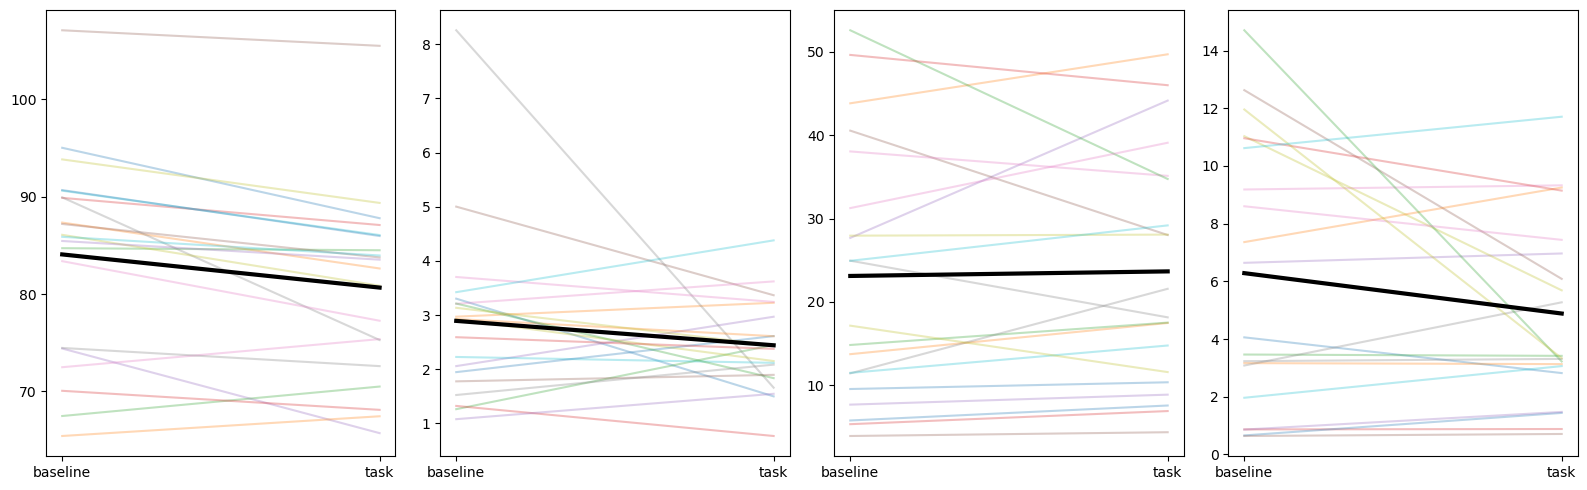

In [37]:
# graph baseline vs task w/ one line /participant

fig, axs = plt.subplots(1, 4, figsize=(16, 5))
for ax, metric in zip(axs, metric_list):
    baseline_column, task_column = wide_format[(metric, 'baseline')], wide_format[(metric, 'task')]
    for participant in wide_format.index:
        ax.plot([0, 1], [baseline_column[participant], task_column[participant]], alpha=0.3)
    ax.plot([0, 1], [baseline_column.mean(), task_column.mean()], color='black', linewidth=3)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['baseline', 'task'])
    
plt.tight_layout(); plt.show()